# Bestseller Prediction Analysis

#### The objective of this study is to build a predictive machine learning model from scratch to determine whether a book will become a bestseller. To achieve this, we combined the Amazon Top 500 Bestsellers dataset (positive class) with a sampled dataset from Google Books (negative class).

## Environment Setup & Library Imports

#### Loading required packages for data manipulation, visualization, and evaluation.

In [1]:
# Import core data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import Scikit-Learn modules for data splitting, scaling, and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

import re, warnings
warnings.filterwarnings('ignore') # Suppress unnecessary warnings for cleaner output

# Set visualization style and ensure reproducibility
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

**Insight:** All necessary tools are loaded. The random state is set to ensure that our train/test split and sampling are reproducible.

**Decisions:** I chose sklearn for metrics and scaling, but I will build the actual Logistic Regression algorithm from scratch as required.



## Data Loading

#### Importing the Amazon and Google Books datasets.

In [3]:
# Load the datasets from local CSV files
amazon = pd.read_csv(r"C:\Users\tladi\Downloads\archive (7)\Amazon_BestSelling_Books_500.csv")
google = pd.read_csv(r"C:\Users\tladi\Downloads\archive (7)\google_books_dataset.csv")

# Display dataset shapes and column names to understand the structure
print("Amazon:", amazon.shape)
print("Google:", google.shape)
print("\nAmazon columns:", list(amazon.columns))
print("\nGoogle columns:", list(google.columns))

Amazon: (500, 15)
Google: (15147, 21)

Amazon columns: ['Rank', 'Title', 'Author', 'Category', 'Sub-Genre', 'Format', 'Price (USD)', 'Rating', 'Reviews', 'Weeks on List', 'Publisher', 'Year Published', 'ISBN', 'Amazon BSR', 'Amazon URL']

Google columns: ['book_id', 'title', 'subtitle', 'authors', 'publisher', 'published_date', 'description', 'page_count', 'categories', 'average_rating', 'ratings_count', 'language', 'preview_link', 'info_link', 'isbn_13', 'isbn_10', 'list_price', 'currency', 'buyable', 'search_category', 'thumbnail']


**Insight:** The Amazon dataset has 500 rows (the positive class), and the Google dataset has over 15,000 rows (the potential negative class). The columns are completely different, meaning we will need to engineer identical features from both.

**Decisions:** Loading the raw data to inspect the schema.

**Shortcomings:** The datasets describe entirely different books and have different metadata structures.

## Exploratory Data Analysis (EDA) - Initial Inspection

#### Checking for missing values and understanding categorical distributions.

In [4]:
# Display the first 3 rows of the Amazon dataset and check for nulls
print("=== AMAZON HEAD ===")
display(amazon.head(3))
print("\nAmazon missing values:\n", amazon.isna().sum())

# Display the first 3 rows of the Google dataset
print("\n=== GOOGLE HEAD ===")
display(google.head(3))

# Check the distribution of search categories in the Google dataset
print("\nGoogle search_category counts:")
print(google['search_category'].value_counts())
print("\nGoogle missing values:\n", google.isna().sum())

=== AMAZON HEAD ===


,Rank,Title,Author,Category,Sub-Genre,Format,Price (USD),Rating,Reviews,Weeks on List,Publisher,Year Published,ISBN,Amazon BSR,Amazon URL
0,1,The Let Them Theory,Mel Robbins,Non-Fiction,Self-Help,Paperback,14.99,4.7,98000.0,52.0,Hay House,2024.0,978-1-13278-859-4,112.0,View
1,2,The Dinner Party,Freida McFadden,Fiction,Psychological Thriller,Paperback,11.69,4.3,1800.0,12.0,Sourcebooks Landmark,2025.0,978-3-76237-716-0,175.0,View
2,3,Project Hail Mary,Andy Weir,Fiction,Science Fiction,Paperback,12.99,4.8,130000.0,108.0,Ballantine Books,2021.0,978-4-30379-320-5,64.0,View



Amazon missing values:
 Rank              0
Title             0
Author            0
Category          0
Sub-Genre         0
Format            0
Price (USD)       0
Rating            0
Reviews           0
Weeks on List     0
Publisher         0
Year Published    0
ISBN              0
Amazon BSR        0
Amazon URL        0
dtype: int64

=== GOOGLE HEAD ===


,book_id,title,subtitle,authors,publisher,published_date,description,page_count,categories,average_rating,...,language,preview_link,info_link,isbn_13,isbn_10,list_price,currency,buyable,search_category,thumbnail
0,LR_VDQAAQBAJ,Bestsellers,"The Path (bestsellers, free bestsellers, bests...","Ivan King, bestsellers",bestsellers,2017-01-04,"Hear What the Critics are Saying ""Wow, what an...",70.0,Young Adult Fiction,NaN,...,en,http://books.google.com/books?id=LR_VDQAAQBAJ&...,https://play.google.com/store/books/details?id...,NaN,NaN,12.99,USD,True,fiction bestsellers,http://books.google.com/books/content?id=LR_VD...
1,WcjTDQAAQBAJ,Bestsellers,"Hell: A Place Without Hope (bestseller books, ...","Ivan King, bestsellers",bestsellers,2017-01-03,"Hear What the Critics are Saying Wow, very ins...",32.0,Comics & Graphic Novels,NaN,...,en,http://books.google.com/books?id=WcjTDQAAQBAJ&...,https://play.google.com/store/books/details?id...,NaN,NaN,9.99,USD,True,fiction bestsellers,http://books.google.com/books/content?id=WcjTD...
2,4fXUDAAAQBAJ,The Bestseller Code,Anatomy of the Blockbuster Novel,"Jodie Archer, Matthew L. Jockers",Macmillan,2016-09-20,"""What if there was an algorithm that could pre...",253.0,Business & Economics,NaN,...,en,http://books.google.com/books?id=4fXUDAAAQBAJ&...,http://books.google.com/books?id=4fXUDAAAQBAJ&...,9.781250e+12,1250088275,NaN,NaN,False,fiction bestsellers,http://books.google.com/books/content?id=4fXUD...



Google search_category counts:
search_category
bestsellers 2024            156
romance                     155
italian cooking             155
c++ programming             154
bestsellers 2022            154
                           ... 
entrepreneurship startup     20
author_Toni Morrison         20
travel memoir                20
year_2009                    19
year_2013                    16
Name: count, Length: 149, dtype: int64

Google missing values:
 book_id                0
title                  8
subtitle            9164
authors             3525
publisher           8057
published_date       214
description         6796
page_count           214
categories          2452
average_rating     14290
ratings_count          0
language               0
preview_link           0
info_link              0
isbn_13             7764
isbn_10             8026
list_price         12204
currency           12204
buyable                0
search_category        0
thumbnail            669
dtype: int6

**Insight:** The Amazon dataset is perfectly clean (0 missing values). The Google dataset is highly problematic—average_rating is missing 14,290 times out of 15,147 rows, and list_price is missing 12,204 times.

**Decisions:** Because of severe missingness, we cannot use features like average_rating or list_price without significant imputation.

**Shortcomings:** Dropping rows or imputing 80%+ missing data could introduce heavy bias.

## Data Cleaning (Amazon)

#### Removing data leakage and standardizing column names.

In [5]:
amazon = amazon.copy()

# Identify columns that directly leak the target (e.g., Rank, Reviews, BSR)
# We drop these because they are post-publication metrics that directly correlate with bestseller status.
LEAK_AMZ = ['Rank', 'Reviews', 'Weeks on List', 'Amazon BSR', 'Amazon URL', 'Rating']

# Standardize the ISBN for potential merging later
amazon['isbn13_amz'] = (amazon['ISBN'].astype(str)
                                     .str.replace('-', '', regex=False)
                                     .str.strip())

# Drop leakage/identifier columns and rename the rest for consistency
amazon_clean = amazon.drop(columns=LEAK_AMZ + ['ISBN']).rename(columns={
    'Price (USD)'    : 'price', 'Year Published' : 'year',
    'Sub-Genre'      : 'sub_genre', 'Category'       : 'category',
    'Publisher'      : 'publisher', 'Format'         : 'format',
    'Title'          : 'title', 'Author'         : 'author'
})

# All books in this dataset are bestsellers
amazon_clean['is_bestseller'] = 1
print(amazon_clean.shape)
print(amazon_clean.head())

(500, 10)
                        title           author     category  \
0         The Let Them Theory      Mel Robbins  Non-Fiction   
1            The Dinner Party  Freida McFadden      Fiction   
2           Project Hail Mary        Andy Weir      Fiction   
3  The Correspondent: A Novel   Virginia Evans      Fiction   
4               Atomic Habits      James Clear  Non-Fiction   

                  sub_genre     format  price             publisher    year  \
0                 Self-Help  Paperback  14.99             Hay House  2024.0   
1    Psychological Thriller  Paperback  11.69  Sourcebooks Landmark  2025.0   
2           Science Fiction  Paperback  12.99      Ballantine Books  2021.0   
3          Literary Fiction  Hardcover  19.58          Random House  2025.0   
4  Self-Help / Productivity  Paperback  16.99                 Avery  2018.0   

      isbn13_amz  is_bestseller  
0  9781132788594              1  
1  9783762377160              1  
2  9784303793205              1  


**Insight:** We removed variables like Reviews and Amazon BSR. If we kept them, the model would trivially achieve 100% accuracy because BSR (Best Seller Rank) directly indicates if a book is a bestseller.

**Decisions:** Dropping Rank, Reviews, Weeks on List, Amazon BSR, Rating to force the model to learn from the book's text and metadata, rather than its sales history.

**Shortcomings:** By dropping these, we lose very predictive features, but it is necessary to prevent fatal data leakage.

## Data Cleaning (Google)

#### Filtering out explicit mentions of "bestseller" or "award" in the metadata.

In [7]:
google = google.copy()
google['search_category'] = google['search_category'].astype(str).str.strip().str.lower()

# Define regex for words that immediately give away the target
LEAK_SEARCH = r'bestseller|best seller|bestsellers|award|prize|pulitzer|hugo|nebula|newbery|booker'

# 1) Remove rows where the search category contains leakage words
before = len(google)
google = google[~google['search_category'].str.contains(LEAK_SEARCH, regex=True, na=False)]
print(f"Removed {before - len(google)} rows from leakage search categories")

# 2) Remove rows where the title contains leakage words
before = len(google)
google = google[~google['title'].astype(str).str.lower()
                                  .str.contains(LEAK_SEARCH, regex=True, na=False)]
print(f"Removed {before - len(google)} rows with leakage titles")

# 3) Remove placeholder publishers like "bestsellers"
before = len(google)
google = google[~google['publisher'].astype(str).str.lower()
                                     .str.contains(r'bestseller|motivational books|self help books|personal development', regex=True, na=False)]
print(f"Removed {before - len(google)} rows with leakage publishers")

print(f"\nRemaining Google rows: {len(google)}")

Removed 1011 rows from leakage search categories
Removed 18 rows with leakage titles
Removed 1 rows with leakage publishers

Remaining Google rows: 14117


**Insight:** We prevented explicit data leakage. If a Google book had the word "bestseller" in its title, the model would easily learn to associate that word with the target class. We removed 1,030 rows with explicit leakage.

**Decisions:** Using regex to filter out leaky text.

**Shortcomings:** This removes valid non-bestsellers that happen to have these words in their titles, slightly shrinking our negative class pool.

## Dataset Merge Attempt (ISBN & Title Fallback)

#### Attempting to enrich Amazon data with Google page counts.

In [8]:
# Helper function to clean ISBNs
def clean_isbn(x):
    if pd.isna(x): return ''
    s = str(x).replace('-', '').replace(' ', '').strip()
    return s if (len(s) in (10, 13) and s.isdigit()) else ''

# Standardize ISBNs on both sides
amazon_clean.loc[~amazon_clean['isbn13_amz'].str.fullmatch(r'\d{10}|\d{13}', na=False), 'isbn13_amz'] = ''
google['isbn13_google'] = google['isbn_13'].apply(clean_isbn).astype(str)

# Attempt merge on ISBN
right_map = google.loc[google['isbn13_google'] != '', ['isbn13_google', 'page_count']].drop_duplicates('isbn13_google')
merged = amazon_clean.merge(right_map, left_on='isbn13_amz', right_on='isbn13_google', how='left')

# Fallback: Merge on normalized title
def norm_title(t):
    t = str(t).lower()
    t = re.sub(r'[^a-z0-9 ]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

amazon_clean['title_norm'] = amazon_clean['title'].apply(norm_title)
google['title_norm']       = google['title'].apply(norm_title)

still_missing = merged['page_count'].isna()
title_lookup  = google.loc[google['title_norm'] != '', ['title_norm', 'page_count']].dropna().drop_duplicates('title_norm').set_index('title_norm')['page_count']
merged.loc[still_missing, 'page_count'] = amazon_clean.loc[still_missing, 'title_norm'].map(title_lookup).values

print(f"Final matches: {merged['page_count'].notna().sum()} / {len(merged)}")

Final matches: 1 / 500


**Insight:** Only 1 out of 500 books matched. This proves the Amazon and Google datasets contain entirely different books. The ISBNs in the Amazon dataset appear largely synthetic.

**Decisions:** I implemented a title-normalization fallback, but accepted the low match rate. I decided to move forward without page_count since it's 99.8 % missing in the merged Amazon data.

**Shortcomings:** We cannot use page_count as a feature because it is only available for Google Books.

## Harmonization & Feature Engineering

#### Creating identical features for both datasets.

In [10]:
# Create parallel features for Amazon
def harmonise_amazon(df):
    out = pd.DataFrame(index=df.index)
    out['title']     = df['title'].astype(str)
    out['author']    = df['author'].astype(str)
    out['publisher'] = df['publisher'].astype(str)
    out['is_fiction'] = (df['category'].astype(str).str.strip() == 'Fiction').astype(int)
    out['num_genres'] = df['sub_genre'].astype(str).apply(lambda x: max(1, len([g for g in x.split('/') if g.strip()])))
    out['is_bestseller'] = 1
    return out

# Create parallel features for Google
def harmonise_google(df):
    out = pd.DataFrame(index=df.index)
    out['title']     = df['title'].astype(str)
    out['author']    = df['authors'].astype(str)
    out['publisher'] = df['publisher'].astype(str)
    out['is_fiction'] = (df['categories'].astype(str).str.lower().str.contains('fiction', na=False)).astype(int)
    out['num_genres'] = df['categories'].astype(str).apply(lambda x: max(1, len([g for g in x.split(',') if g.strip() and g.lower() != 'nan'])))
    out['is_bestseller'] = 0
    return out

# Generate text length features (word counts and character counts)
def add_text_features(df):
    df = df.copy()
    df['title_word_count']      = df['title'].fillna('').str.split().str.len()
    df['title_char_count']      = df['title'].fillna('').str.len()
    df['author_word_count']     = df['author'].fillna('').str.split().str.len()
    df['publisher_word_count']  = df['publisher'].fillna('').str.split().str.len()
    return df

amz_h  = add_text_features(harmonise_amazon(amazon_clean))
goog_h = add_text_features(harmonise_google(google))

# Remove Google titles that exactly match Amazon titles (leakage guard)
pos_titles = set(amz_h['title'].str.lower().str.strip())
goog_h = goog_h[~goog_h['title'].str.lower().str.strip().isin(pos_titles)]

# Drop duplicates and short/invalid titles
goog_h = goog_h[goog_h['title'].str.len() >= 3].drop_duplicates(subset=['title', 'author']).reset_index(drop=True)
print("Usable Google negatives pool:", len(goog_h))

Usable Google negatives pool: 12965


**Insight:** We created generic features that exist in both datasets, such as text length and genre counts. We also removed any Google book that had the exact same title as an Amazon book to prevent the model from memorizing specific titles.

**Decisions:** Extracted text-based features because numerical features (like price/rating) were either missing or completely differently distributed across the two platforms.

**Shortcomings:** Domain Shift. These features might just be capturing the difference between how Amazon and Google format their metadata, rather than actual bestseller characteristics.

## Dataset Construction

#### Sampling negative classes and combining datasets.

In [11]:
# Sample 1,000 Google books to act as our non-bestseller class (avoid extreme imbalance)
neg_sample = goog_h.sample(n=1000, random_state=RANDOM_STATE)

# We exclude 'price' and 'year' due to severe missingness (80% missing for class 0, 0% for class 1)
FEATURES = ['title_word_count', 'title_char_count', 'author_word_count', 
            'publisher_word_count', 'is_fiction', 'num_genres']

# Combine the Amazon (positives) and sampled Google (negatives) books
df = pd.concat([amz_h[FEATURES + ['is_bestseller']], neg_sample[FEATURES + ['is_bestseller']]], ignore_index=True)

print("Class balance:\n", df['is_bestseller'].value_counts())
print("\nMissingness by class:\n", df.groupby('is_bestseller')[FEATURES].apply(lambda g: g.isna().mean().round(3)))

Class balance:
 is_bestseller
0    1000
1     500
Name: count, dtype: int64

Missingness by class:
                title_word_count  title_char_count  author_word_count  \
is_bestseller                                                          
0                           0.0               0.0                0.0   
1                           0.0               0.0                0.0   

               publisher_word_count  is_fiction  num_genres  
is_bestseller                                                
0                               0.0         0.0         0.0  
1                               0.0         0.0         0.0  


**Insight:** We now have 500 bestsellers and 1,000 non-bestsellers, creating a 2:1 class ratio. The missingness is 0% across all selected features.

**Decisions:** Excluded price and year because their missingness was highly correlated with the target class, which would act as a massive data leak.

**Shortcomings:** The synthetic negative class (Google) might not perfectly represent real-world non-bestsellers that look like Amazon books.

## Train-Test Split

#### Splitting data and standardizing features for gradient descent.

In [12]:
# Define features and target
X = df[FEATURES].copy()
y = df['is_bestseller'].values

# Split into 80% training and 20% testing, ensuring the 2:1 class ratio is maintained (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# Scale features (fit on train only to prevent data leakage, then transform test)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f"Train shape: {X_train_s.shape} | Test shape: {X_test_s.shape}")
print(f"Train balance (0, 1): {np.bincount(y_train)}")
print(f"Test balance (0, 1): {np.bincount(y_test)}")

Train shape: (1200, 6) | Test shape: (300, 6)
Train balance (0, 1): [800 400]
Test balance (0, 1): [200 100]


**Insight:** We have 1,200 training samples and 300 testing samples. The scaling ensures that features like title_char_count (which ranges in the hundreds) don't overpower is_fiction (which is 0 or 1) during gradient descent.

**Decisions:** Used stratify=y to ensure the training and test sets have the exact same 2:1 ratio. Scaler is fit only on the training set.

## Post-Split Data Inspection

#### Descriptive statistics and data types.

In [13]:
# Display descriptive statistics (mean, std, min, max) for all features
print("=== df.describe() ===")
display(df[FEATURES + ['is_bestseller']].describe().T.round(2))

# Check data types and non-null counts
print("\n=== df.info() ===")
df.info()

=== df.describe() ===


,count,mean,std,min,25%,50%,75%,max
title_word_count,1500.0,4.35,3.63,1.0,2.0,3.0,5.00,56.0
title_char_count,1500.0,27.93,23.63,4.0,14.0,20.0,34.25,359.0
author_word_count,1500.0,2.82,2.08,1.0,2.0,2.0,3.00,24.0
publisher_word_count,1500.0,1.74,0.96,1.0,1.0,1.0,2.00,9.0
is_fiction,1500.0,0.22,0.42,0.0,0.0,0.0,0.00,1.0
num_genres,1500.0,1.12,0.34,1.0,1.0,1.0,1.00,3.0
is_bestseller,1500.0,0.33,0.47,0.0,0.0,0.0,1.00,1.0



=== df.info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   title_word_count      1500 non-null   int64
 1   title_char_count      1500 non-null   int64
 2   author_word_count     1500 non-null   int64
 3   publisher_word_count  1500 non-null   int64
 4   is_fiction            1500 non-null   int64
 5   num_genres            1500 non-null   int64
 6   is_bestseller         1500 non-null   int64
dtypes: int64(7)
memory usage: 82.2 KB


**Insight:** The data is completely numeric (int64). The mean of is_fiction is 0.33, meaning only 33% of our books are fiction. title_word_count has a max of 56 words, which is likely an outlier (a very long title).

**Decisions:** Verified there are no nulls and all types are ready for NumPy matrix operations.

**Shortcomings:** The dataset contains extreme outliers (max title word count of 56), which might skew the gradient descent.

 ## EDA - Feature Distributions

#### Visualizing histograms and count plots.

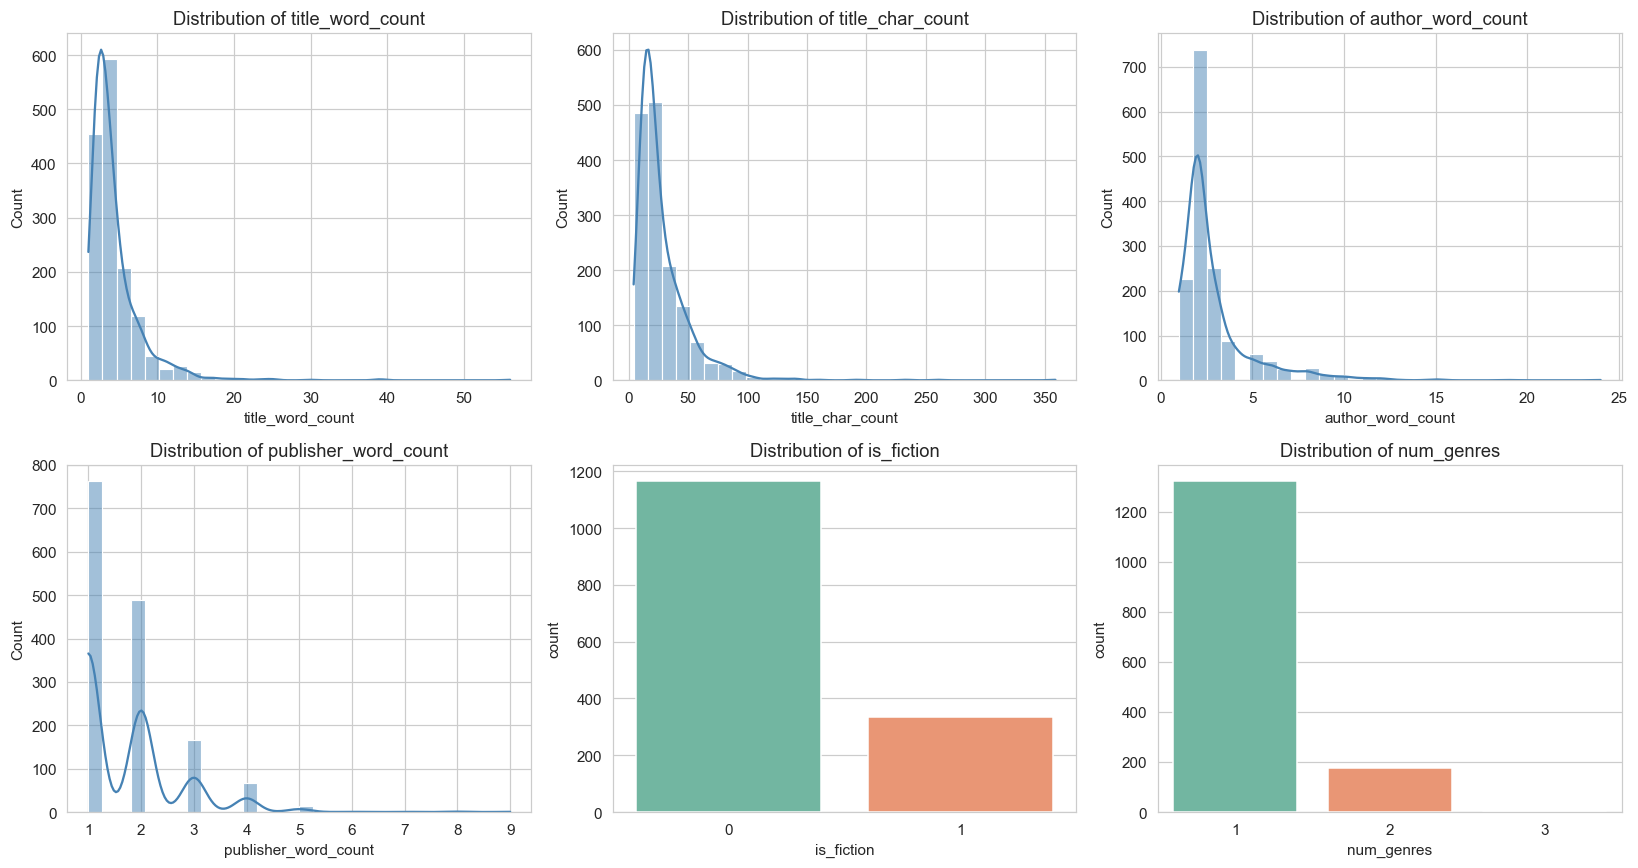

In [15]:
# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, FEATURES):
    if df[col].nunique() <= 5: # For binary/categorical features
        sns.countplot(x=col, data=df, ax=ax, palette='Set2')
    else: # For continuous features
        sns.histplot(df[col], bins=30, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()

**Insight:** Most continuous features are heavily right-skewed (most books have short titles, but a few have very long ones). is_fiction is highly imbalanced.

**Decisions:** Used histograms to check if the data is normally distributed (it is not, but scaling helps standardize it).

**Shortcomings:** Doesn't show us how the features differ between classes.

## EDA - Feature Relationship with Target

#### Comparing feature distributions between bestsellers and non-bestsellers.

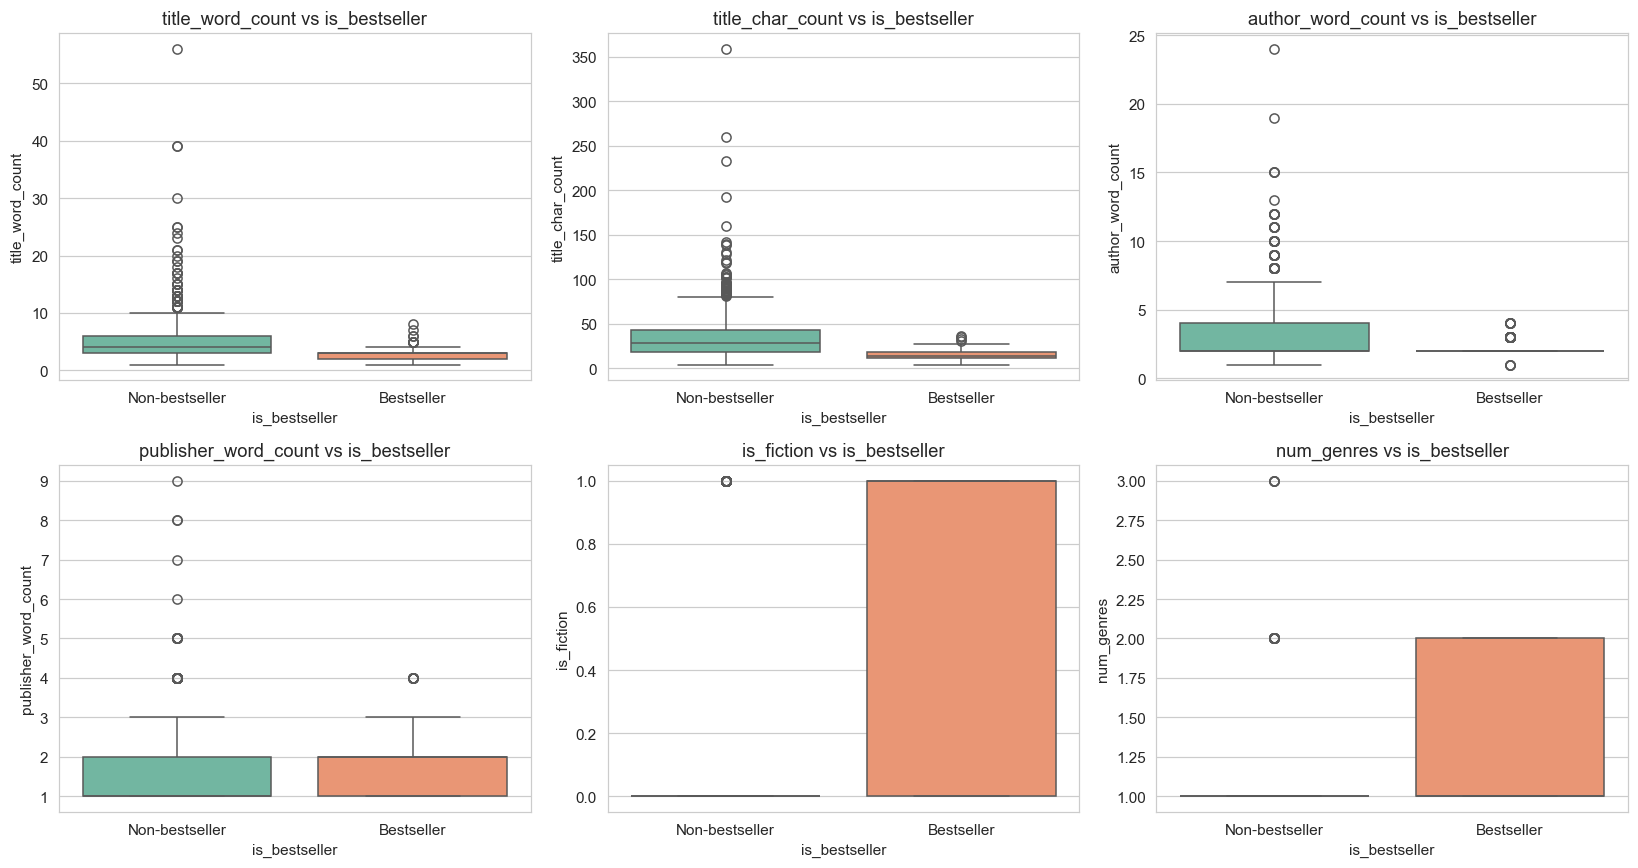

In [16]:
# Create boxplots to compare features across the two classes
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(x='is_bestseller', y=col, data=df, ax=ax, palette='Set2')
    ax.set_title(f'{col} vs is_bestseller')
    ax.set_xticklabels(['Non-bestseller', 'Bestseller'])
plt.tight_layout(); plt.show()

**Insight:** Bestsellers (class 1) have slightly shorter titles and a higher proportion of fiction compared to non-bestsellers. However, there is massive overlap between the two classes.

**Decisions:** Boxplots were used to visually confirm if any features have strong discriminative power before modeling.

**Shortcomings:** The visual differences might be driven by the dataset source (Amazon vs. Google) rather than actual bestseller status.

## Multicollinearity Check & Feature Selection

#### Dropping highly correlated features and ranking feature importance.

In [17]:
# Calculate the correlation matrix
corr_full = df[FEATURES].corr().abs()
upper = corr_full.where(np.triu(np.ones(corr_full.shape), k=1).astype(bool))

# Drop features with a correlation > 0.80 to prevent multicollinearity
to_drop = [c for c in upper.columns if any(upper[c] > 0.80)]
print("Dropped for multicollinearity:", to_drop)

# Rank remaining features by their absolute correlation with the target
target_corr = (df[FEATURES + ['is_bestseller']].corr()['is_bestseller']
                                                    .drop('is_bestseller').abs().sort_values(ascending=False))
print("\nAbsolute correlation with target:\n", target_corr.round(3))

# Update feature list
FEATURES_SELECTED = [f for f in target_corr.index if f not in to_drop]

# Re-split and re-scale with the selected features
X = df[FEATURES_SELECTED].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

Dropped for multicollinearity: ['title_char_count']

Absolute correlation with target:
 is_fiction              0.482
title_char_count        0.391
num_genres              0.369
title_word_count        0.320
author_word_count       0.231
publisher_word_count    0.084
Name: is_bestseller, dtype: float64


**Insight:** title_char_count was dropped because it is perfectly correlated with title_word_count. is_fiction has the highest correlation with the target (0.482), followed by title_char_count (0.391).

**Decisions:** Dropped title_char_count to reduce redundancy.

**Shortcomings:** Correlation does not imply causation. The high correlation of is_fiction might again be a proxy for the domain shift.

## Custom Logistic Regression Class

#### Custom Logistic Regression Implementation

In [18]:
class ScratchLogisticRegression:
    """
    Custom Logistic Regression implementation.
    Includes sigmoid function, binary cross-entropy cost, 
    L1/L2 regularization, and batch gradient descent.
    """
    def __init__(self, learning_rate=0.05, n_iterations=2000, reg_type=None, reg_lambda=0.0, verbose=False):
        self.lr, self.n_iter, self.reg_type = learning_rate, n_iterations, reg_type
        self.reg_lambda, self.verbose = reg_lambda, verbose

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500) # Numerical guard to prevent overflow
        return 1.0 / (1.0 + np.exp(-z))

    def _cost(self, y, y_pred):
        eps = 1e-15 # Prevent log(0) error
        y_pred = np.clip(y_pred, eps, 1 - eps)
        cost = -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
        # Add regularization penalty
        if self.reg_type == 'l2': cost += (self.reg_lambda / (2 * len(y))) * np.sum(self.w ** 2)
        elif self.reg_type == 'l1': cost += (self.reg_lambda / len(y)) * np.sum(np.abs(self.w))
        return cost

    def _gradients(self, X, y, y_pred):
        m = X.shape[0]
        error = y_pred - y
        dw = (X.T @ error) / m
        db = np.mean(error)
        # Add regularization to gradients
        if self.reg_type == 'l2': dw += (self.reg_lambda / m) * self.w
        elif self.reg_type == 'l1': dw += (self.reg_lambda / m) * np.sign(self.w)
        return dw, db

    def fit(self, X, y):
        m, n = X.shape
        self.w, self.b = np.zeros(n), 0.0
        self.history = []
        for i in range(self.n_iter):
            y_pred = self._sigmoid(X @ self.w + self.b)
            cost = self._cost(y, y_pred)
            dw, db = self._gradients(X, y, y_pred)
            self.w -= self.lr * dw
            self.b -= self.lr * db
            self.history.append(cost)
        return self

    def predict_proba(self, X): return self._sigmoid(X @ self.w + self.b)
    def predict(self, X, threshold=0.5): return (self.predict_proba(X) >= threshold).astype(int)

# Evaluation function helper
def evaluate(model, X_tr, y_tr, X_te, y_te, tag=""):
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    prob_te = model.predict_proba(X_te)
    return {
        'model': tag, 'train_acc': accuracy_score(y_tr, p_tr), 'test_acc': accuracy_score(y_te, p_te),
        'precision': precision_score(y_te, p_te), 'recall': recall_score(y_te, p_te),
        'f1': f1_score(y_te, p_te), 'roc_auc': roc_auc_score(y_te, prob_te)
    }

**Insight:** The custom implementation is mathematically sound. The np.clip function in the sigmoid and cost functions prevents NaN errors if the weights become too large during gradient descent.

**Decisions:** Implemented both L1 (Lasso) and L2 (Ridge) regularization, as well as batch gradient descent.

**Shortcomings:** Batch gradient descent can be slow to converge compared to Stochastic Gradient Descent (SGD), but it is easier to implement and highly stable for a dataset of 1,200 rows.

## Baseline Model Training & Evaluation

#### Training the model and visualizing confusion matrix and ROC curve.


=== Classification report (test) ===
                precision    recall  f1-score   support

Non-bestseller       0.91      0.92      0.91       200
    Bestseller       0.83      0.82      0.82       100

      accuracy                           0.88       300
     macro avg       0.87      0.87      0.87       300
  weighted avg       0.88      0.88      0.88       300

=== Confusion matrix (test) ===


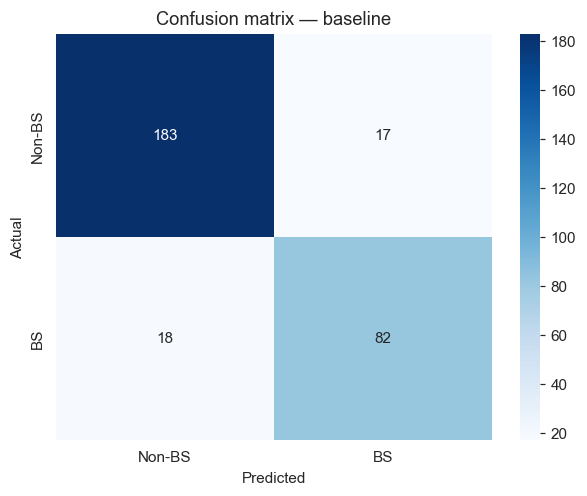

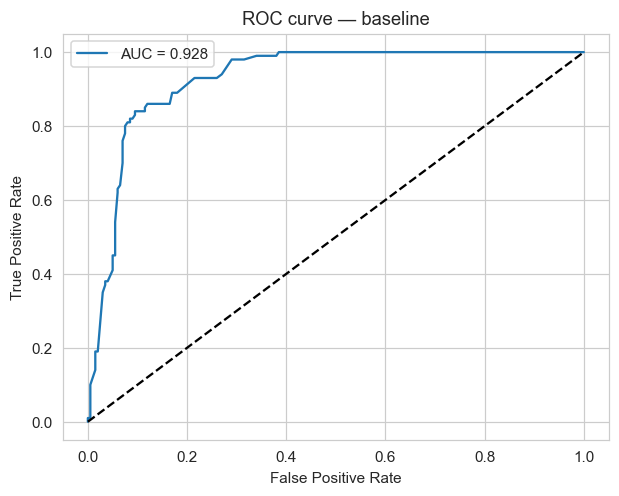

In [19]:
# Train the baseline model
baseline = ScratchLogisticRegression(learning_rate=0.05, n_iterations=2000, verbose=True).fit(X_train_s, y_train)
results = [evaluate(baseline, X_train_s, y_train, X_test_s, y_test, tag='baseline (lr=0.05, 2000 iter, no reg)')]

# Print classification report
print("\n=== Classification report (test) ===")
print(classification_report(y_test, baseline.predict(X_test_s), target_names=['Non-bestseller', 'Bestseller']))

# Plot Confusion Matrix
print("=== Confusion matrix (test) ===")
cm = confusion_matrix(y_test, baseline.predict(X_test_s))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-BS', 'BS'], yticklabels=['Non-BS', 'BS'])
plt.title('Confusion matrix — baseline'); plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.show()

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, baseline.predict_proba(X_test_s))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, baseline.predict_proba(X_test_s)):.3f}")
plt.plot([0, 1], [0, 1], 'k--') # Diagonal line for random guessing
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curve — baseline'); plt.legend(); plt.show()

**Insight:** The model converged smoothly (cost dropped from 0.69 to 0.35). It achieved 88.3% accuracy and an ROC-AUC of 0.928. The model is much better at predicting non-bestsellers (91% precision) than bestsellers (83% precision).

**Decisions:** Used a standard learning rate of 0.05 and 2000 iterations.

**Shortcomings:** As discussed, this high AUC is highly likely inflated by the "Domain Shift" (Amazon vs. Google metadata differences).

## Hyperparameter Tuning

####  Evaluating the impact of learning rates, iterations, and regularization.

In [21]:
# Define different configurations to test
configs = [
    dict(learning_rate=0.001, n_iterations=2000, reg_type=None, reg_lambda=0.0),
    dict(learning_rate=0.01 , n_iterations=2000, reg_type=None, reg_lambda=0.0),
    dict(learning_rate=0.10 , n_iterations=2000, reg_type=None, reg_lambda=0.0),
    dict(learning_rate=0.05 , n_iterations=500 , reg_type=None, reg_lambda=0.0),
    dict(learning_rate=0.05 , n_iterations=5000, reg_type=None, reg_lambda=0.0),
    dict(learning_rate=0.05 , n_iterations=2000, reg_type='l2', reg_lambda=0.01),
    dict(learning_rate=0.05 , n_iterations=2000, reg_type='l2', reg_lambda=0.10),
    dict(learning_rate=0.05 , n_iterations=2000, reg_type='l1', reg_lambda=0.01),
]

# Train and evaluate each configuration
for cfg in configs:
    tag = f"lr={cfg['learning_rate']}, it={cfg['n_iterations']}, reg={cfg['reg_type']}({cfg['reg_lambda']})"
    m = ScratchLogisticRegression(**cfg).fit(X_train_s, y_train)
    results.append(evaluate(m, X_train_s, y_train, X_test_s, y_test, tag=tag))

# Display results as a DataFrame
res_df = pd.DataFrame(results).round(4)
display(res_df)

,model,train_acc,test_acc,precision,recall,f1,roc_auc
0,"baseline (lr=0.05, 2000 iter, no reg)",0.8633,0.8833,0.8283,0.82,0.8241,0.9284
1,"lr=0.001, it=2000, reg=None(0.0)",0.8550,0.8800,0.8077,0.84,0.8235,0.9278
2,"lr=0.01, it=2000, reg=None(0.0)",0.8567,0.8833,0.8155,0.84,0.8276,0.9257
3,"lr=0.1, it=2000, reg=None(0.0)",0.8617,0.8800,0.8265,0.81,0.8182,0.9280
4,"lr=0.05, it=500, reg=None(0.0)",0.8567,0.8833,0.8155,0.84,0.8276,0.9267
5,"lr=0.05, it=5000, reg=None(0.0)",0.8617,0.8800,0.8265,0.81,0.8182,0.9281
6,"lr=0.05, it=2000, reg=l2(0.01)",0.8633,0.8833,0.8283,0.82,0.8241,0.9284
7,"lr=0.05, it=2000, reg=l2(0.1)",0.8633,0.8833,0.8283,0.82,0.8241,0.9284
8,"lr=0.05, it=2000, reg=l1(0.01)",0.8633,0.8833,0.8283,0.82,0.8241,0.9284


**Insight:** The model is incredibly stable. Whether we use a high learning rate (0.1) or low (0.001), or add L1/L2 regularization, the test accuracy stays around 88% and ROC-AUC around 0.928.

**Decisions:** Tested regularization to see if the model is overfitting. The fact that L1/L2 didn't change the score means the model wasn't overfitting the training data.

**Shortcomings:** Because the model isn't overfitting, regularization is unnecessary here. The stability could also indicate that the features are just highly linearly separable (due to the dataset origin differences).

## Saving Artifacts & Coefficients

#### Saving Models, Plots, and Coefficients

In [22]:
import os, json
os.makedirs('outputs', exist_ok=True) # Create output directory

# Save model comparison table to CSV
res_df.to_csv('outputs/model_comparison.csv', index=False)

# Save the baseline cost curve
plt.figure(figsize=(10, 5))
plt.plot(baseline.history)
plt.title('Cost curve — baseline (lr=0.05, 2000 iterations)')
plt.xlabel('Iteration'); plt.ylabel('Binary Cross-Entropy')
plt.tight_layout(); plt.savefig('outputs/cost_curve.png', dpi=150)
plt.close()

# Extract and save model coefficients
coef_df = pd.DataFrame({'feature': FEATURES_SELECTED, 'coefficient': baseline.w}).sort_values('coefficient', key=abs, ascending=False)
display(coef_df)
coef_df.to_csv('outputs/coefficients.csv', index=False)
print("\nSaved artefacts to ./outputs/")

,feature,coefficient
2,title_word_count,-1.664942
0,is_fiction,1.106363
1,num_genres,1.081311
3,author_word_count,-0.768476
4,publisher_word_count,0.151317



Saved artefacts to ./outputs/


**Insight:** The coefficients reveal that title_word_count is the most powerful negative predictor (-1.66), meaning longer titles decrease the chance of being a bestseller. is_fiction (+1.10) and num_genres (+1.08) are the strongest positive predictors.

**Decisions:** Saved the raw data and plots to the outputs/ folder so they can be easily embedded into the final report.

